## Запуск

Запуск из папки hw1:

```bash
pip install -r requirements.txt
jupyter nbconvert --to notebook --execute --inplace experiments.ipynb
```

данные скачиваются сами при первом запуске в папку data/ (архив ~47 МБ с zenodo), если не скачались, то архив можно скачать руками по ссылке из п.1 и распаковать в data/

сид фиксирован SEED = 42, даты сплита и сетки параметров заданы в ячейках ниже

In [1]:
import tarfile
from pathlib import Path
from urllib.request import urlretrieve

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from scipy import sparse

from models.utils import to_csr, evaluate
from models.popular import Popular
from models.knn import ItemKNN
from models.als import ALSImplicit
from models.ease import EASE
from models.fm import FactorizationMachine
from models.ials_custom import CustomTargetALS, custom_target

SEED = 42
K = 10
DATA_DIR = Path("data")
RAW_DIR = DATA_DIR / "KuaiRand-Pure" / "data"
DATA_URL = "https://zenodo.org/records/10439422/files/KuaiRand-Pure.tar.gz"
VALID_START = 20220429
TEST_START = 20220503

## 1. Данные

KuaiRand-Pure: логи ленты коротких роликов из приложения Kuaishou с 9 апреля по 8 мая 2022 года.

датасет: https://kuairand.com, статья: https://arxiv.org/abs/2208.08696. скачиваем из: https://zenodo.org/records/10439422

KuaiRand-Pure это версия KuaiRand, в которой оставили логи только по 7 583 видео из всего пула кандидатов, после очистки осталось ~1.3 млн взаимодействий

файлы:
- log_standard_4_08_to_4_21_pure.csv , log_standard_4_22_to_5_08_pure.csv: показы видео в обычной ленте
- user_features_pure.csv: признаки юзеров
- video_features_basic_pure.csv: признаки видео

1 строка лога <-> 1 показ видео юзеру

поля:
- user_id, video_id: id юзеров и видео
- date, time_ms: дата и время показа
- is_click: клик по видео. В ленте с 1 колонкой видео запускается само, тогда кликом будет просмотр > 7сек
- long_view: просмотр > 18 сек или до конца 
- is_like, is_follow, is_comment, is_forward: лайк, подписка на автора, комментарий, репост
- is_hate: дизлайк
- play_time_ms, duration_ms: время просмотра и длительность ролика

рекомендуем каждому юзеру 10 видео, которые ему еще не показывали, релевантное видео это по которому юзер кликнул в моменте оценки (is_click = 1)

In [2]:
if not RAW_DIR.exists():
    DATA_DIR.mkdir(exist_ok=True)
    archive = DATA_DIR / "KuaiRand-Pure.tar.gz"
    urlretrieve(DATA_URL, archive)
    with tarfile.open(archive) as tar:
        tar.extractall(DATA_DIR, filter="data")

log = pd.concat([
    pd.read_csv(RAW_DIR / "log_standard_4_08_to_4_21_pure.csv"),
    pd.read_csv(RAW_DIR / "log_standard_4_22_to_5_08_pure.csv"),
], ignore_index=True)
users = pd.read_csv(RAW_DIR / "user_features_pure.csv")
videos = pd.read_csv(RAW_DIR / "video_features_basic_pure.csv")
print("# показов:", len(log))
print("# кликов:", log.is_click.sum())
print("# юзеров:", log.user_id.nunique())
print("# роликов:", log.video_id.nunique())
log.head()

# показов: 1436609
# кликов: 660342
# юзеров: 27077
# роликов: 7551


,user_id,video_id,date,hourmin,time_ms,is_click,is_like,is_follow,is_comment,is_forward,is_hate,long_view,play_time_ms,duration_ms,profile_stay_time,comment_stay_time,is_profile_enter,is_rand,tab
0,0,1527,20220411,1900,1649675512388,0,0,0,0,0,0,0,1385,209900,0,0,0,0,1
1,0,7405,20220416,2000,1650111976017,0,0,0,0,0,0,0,0,65400,0,0,0,0,0
2,0,6026,20220420,1600,1650444367095,0,0,0,0,0,0,0,1405,170833,0,0,0,0,1
3,1,6354,20220411,1100,1649645295928,0,0,0,0,0,0,0,0,255160,0,0,0,0,8
4,1,3645,20220411,1100,1649648827559,0,0,0,0,0,0,0,1970,79733,0,0,0,0,1


## 2. EDA и подготовка данных

In [3]:
print("# пропусков:", log.isna().sum().sum())
print("# полных дубликатов строк:", log.duplicated().sum())
print("# повторных показов пары юзер-видео:", log.duplicated(["user_id", "video_id"]).sum())
print("# рекламных видео:", (videos.video_type == "AD").sum())
missing = pd.concat([users.isna().sum(), videos.isna().sum()])
missing[missing > 0]

# пропусков: 0


# полных дубликатов строк: 21987
# повторных показов пары юзер-видео: 61609
# рекламных видео: 76


onehot_feat4      874
onehot_feat12     714
onehot_feat13     714
onehot_feat14     714
onehot_feat15     714
onehot_feat16     714
onehot_feat17     714
video_duration    239
music_type        203
tag                96
dtype: int64

- пропусков нет в логах, в 7 признаках юзеров они есть и в 3 признаках видео: длительность, тип музыки, теги. 

- строки не удаляем, в FM пропуск будет отдельной категорией

- полных дубликатов 21 987, всего повторных показов одной пары 61 609 (~4%), повторные показы объединяем в 1 взаимодействие: время беру от первого показа, реакции оставляю максимальные. Для моделей объединяем отдельно внутри train, val и test, иначе клик из будущего переносится на ранний показ и попадает в train

- рекламные видео удалю: это показывает рекламная система, а не рекомендации

In [4]:
SIGNALS = ["is_click", "long_view", "is_like", "is_follow", "is_comment", "is_forward", "is_hate"]
log = log[~log.video_id.isin(videos.loc[videos.video_type == "AD", "video_id"])]


def aggregate(frame):
    return frame.groupby(["user_id", "video_id"], as_index=False).agg(
        {"time_ms": "min", "date": "min", **{col: "max" for col in SIGNALS}}
    )


df = aggregate(log)
print("# взаимодействий:", len(df))

# взаимодействий: 1360299


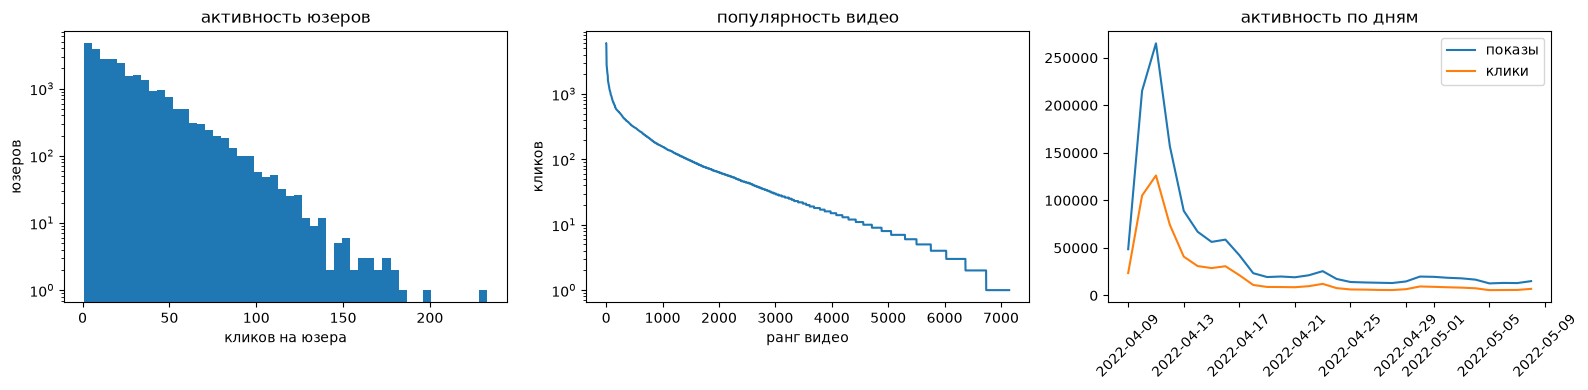

медиана кликов: 18
доля кликов у 10% самых популярных видео: 0.63
плотность матрицы кликов: 0.0034
доля показов с кликом: 0.47


In [5]:
clicks = df[df.is_click == 1]
user_clicks = clicks.user_id.value_counts()
item_clicks = clicks.video_id.value_counts()
daily = df.groupby("date").agg(shows=("is_click", "size"), clicks=("is_click", "sum"))
days = pd.to_datetime(daily.index.astype(str))

fig, axes = plt.subplots(1, 3, figsize=(16, 4))
axes[0].hist(user_clicks, bins=50, log=True)
axes[0].set(title="активность юзеров", xlabel="кликов на юзера", ylabel="юзеров")
axes[1].plot(np.arange(1, len(item_clicks) + 1), item_clicks.to_numpy())
axes[1].set(title="популярность видео", xlabel="ранг видео", ylabel="кликов", yscale="log")
axes[2].plot(days, daily.shows, label="показы")
axes[2].plot(days, daily.clicks, label="клики")
axes[2].set(title="активность по дням")
axes[2].legend()
axes[2].tick_params(axis="x", rotation=45)
plt.tight_layout()
plt.show()

print(f"медиана кликов: {user_clicks.median():.0f}")
print(f"доля кликов у 10% самых популярных видео: {item_clicks.head(len(item_clicks) // 10).sum() / len(clicks):.2f}")
print(f"плотность матрицы кликов: {len(clicks) / (len(user_clicks) * len(item_clicks)):.4f}")
print(f"доля показов с кликом: {df.is_click.mean():.2f}")

- медиана 18 кликов, у самых активных больше 200
- 10% самых популярных видео собирают 63% кликов, поэтому популярность будет хорошим бейзлайном
- клик есть почти у половины показов
- После 10-11 апреля активность сильно падает, в конце периода показов в 20 раз меньше, тк все видео загружены 9-11 апреля, и со временем они становтся менее актулаьными,поэтому разбиение делаем по времени

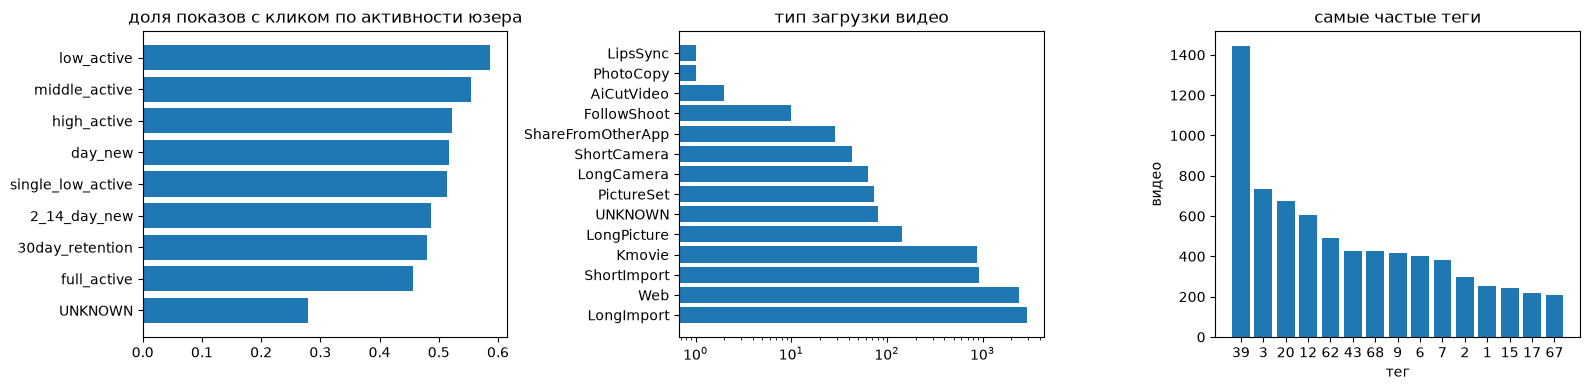

даты загрузки видео: 2022-04-09 2022-04-11
медиана длительности видео, с: 81
# тегов: 46


In [6]:
shows = df.merge(users[["user_id", "user_active_degree"]], on="user_id")
ctr_by_activity = shows.groupby("user_active_degree").is_click.mean().sort_values()
upload_types = videos.upload_type.value_counts()
tags = videos.tag.dropna().str.split(",").explode().value_counts().head(15)

fig, axes = plt.subplots(1, 3, figsize=(16, 4))
axes[0].barh(ctr_by_activity.index, ctr_by_activity.to_numpy())
axes[0].set(title="доля показов с кликом по активности юзера")
axes[1].barh(upload_types.index, upload_types.to_numpy())
axes[1].set(title="тип загрузки видео", xscale="log")
axes[2].bar(tags.index, tags.to_numpy())
axes[2].set(title="самые частые теги", xlabel="тег", ylabel="видео")
plt.tight_layout()
plt.show()

print("даты загрузки видео:", videos.upload_dt.min(), videos.upload_dt.max())
print(f"медиана длительности видео, с: {videos.video_duration.median() / 1000:.0f}")
print("# тегов:", videos.tag.dropna().str.split(",").explode().nunique())

- доля показов с кликом после него зависит от активности юзера: у самой большой группы full_active она 0.46, у middle_active и low_active 0.55-0.59,  полезно для FM.
- большая часть видео загружена 4 способами: LongImport, Web, ShortImport, Kmovie
- 46 тегов, у 76% видео 1 тег
- все видео загружены 9-11 апреля, поэтому новых в периоде оценки почти нет

уберем юзеров и видео у которых <5 кликов( повторяем фильтр пока выборка меняется), их надо убрать, тк по ним коллаборативные модели почти ничего не выучат, а метрики у них шумные. Клики считаем только в train (до 29 апреля), чтобы фильтр не смотрел в будущее, список юзеров и видео дальше не меняем

In [7]:
train = aggregate(log[log.date < VALID_START])
valid = aggregate(log[(log.date >= VALID_START) & (log.date < TEST_START)])
test = aggregate(log[log.date >= TEST_START])
train_valid = aggregate(log[log.date < TEST_START])

min_clkcs = 5
kept = train
while True:
    clicks = kept[kept.is_click == 1]
    user_clicks = clicks.user_id.value_counts()
    item_clicks = clicks.video_id.value_counts()
    filtered = kept[
        kept.user_id.isin(user_clicks[user_clicks >= min_clkcs].index)
        & kept.video_id.isin(item_clicks[item_clicks >= min_clkcs].index)
    ]
    if len(filtered) == len(kept):
        break
    kept = filtered

user_ids = np.sort(kept.user_id.unique())
item_ids = np.sort(kept.video_id.unique())
n_users, n_items = len(user_ids), len(item_ids)


def select(frame):
    frame = frame[frame.user_id.isin(user_ids) & frame.video_id.isin(item_ids)]
    return frame.assign(user_idx=np.searchsorted(user_ids, frame.user_id), item_idx=np.searchsorted(item_ids, frame.video_id))


final = select(pd.concat([train, valid, test]))
train, train_valid = select(train), select(train_valid)
print("# взаимодействий:", len(final))
print("# кликов:", final.is_click.sum())
print("# юзеров:", n_users)
print("# видео:", n_items)

# взаимодействий: 1273636
# кликов: 623417
# юзеров: 21577
# видео: 5549


## 3. Протокол оценки

сплит по времени:
- train: 9-28 апреля
- validation: 29 апреля-2 мая
- test: 3-8 мая

Гиперпараметры: обучаем на train, считаем метрики на val, каждую модель с лучшими параметрами обучаем на train + val и считаем метрики на test, до этого test не трогаем

Правила оценки одинаковые для всех моделей:
- юзеры и видео: те, что остались в train после фильтра, при обучении на train + val список не меняется
- новые юзеры и видео (их нет в train после фильтра) не попадают ни в обучение, ни в оценку
- кандидаты: все видео, у которых есть клик в обучающей части
- видео, которые юзеру уже показывали в обучающей части, из рекомендаций исключаются
- релевантные видео: клики в периоде оценки по видео, которые юзеру раньше не показывали

Все модели, кроме iALS с кастомным таргетом, обучаются на бинарной матрице кликов X. Кастомный таргет меняет только обучение, критерий релевантности на test остается тем же.

Метрики при K = 10:
- NDCG@10, основная метрика, в ленте юзер сначала видит верх списка, поэтому важно, на каких позициях стоят релевантные видео:
$$DCG_k=\sum_{i=1}^{k}\frac{rel_i}{\log_2(i+1)},\qquad NDCG_k=\frac{DCG_k}{IDCG_k}$$
$rel_i=1$ если видео на позиции $i$ релевантное, иначе 0
- Recall@10: доля будущих кликов юзера, которые попали в топ-10:
$$\operatorname{Recall@K}_u=\frac{|T_u\cap G_u|}{|G_u|}$$
$T_u$ это топ-K рекомендаций юзера, $G_u$ его релевантные видео
- Coverage: доля видео, которые попали хотя бы в один топ-10, чтобы увидеть, насколько модель смещена к популярным видео:
$$Coverage=\frac{|I_P|}{|I|}$$
$I_P$ это видео которые хоть раз рекомендовали, $I$ это все видео-кандидаты

метрики усредняются по юзерам

In [8]:
for name, part in [("train", train), ("validation", select(valid)), ("test", select(test))]:
    print(f"{name}: показов {len(part)}, кликов {part.is_click.sum()}")

train: показов 1130542, кликов 556809
validation: показов 64703, кликов 30631
test: показов 78391, кликов 35977


In [9]:
def make_heldout(history, future):
    clicks = history[history.is_click == 1]
    candidates = np.zeros(n_items, dtype=bool)
    candidates[clicks.item_idx.unique()] = True
    relevant = future[future.is_click == 1]
    print("# кликов в периоде оценки:", len(relevant))
    print("# кликов у новых юзеров:", (~relevant.user_id.isin(user_ids)).sum())
    print("# кликов по новым видео:", (~relevant.video_id.isin(item_ids)).sum())
    relevant = select(relevant)
    seen = to_csr(history, n_users, n_items)
    shown = np.asarray(seen[relevant.user_idx.to_numpy(), relevant.item_idx.to_numpy()]).ravel() > 0
    print("# кликов по уже показанным видео:", shown.sum())
    relevant = relevant[~shown]
    heldout = {u: items.to_numpy() for u, items in relevant.groupby("user_idx").item_idx}
    print("# юзеров в оценке:", len(heldout))
    return heldout, candidates


heldout_valid, candidates_train = make_heldout(train, valid)

# кликов в периоде оценки: 34117
# кликов у новых юзеров: 3244
# кликов по новым видео: 275
# кликов по уже показанным видео: 476
# юзеров в оценке: 12085


In [10]:
heldout_test, candidates_full = make_heldout(train_valid, test)

# кликов в периоде оценки: 40216
# кликов у новых юзеров: 3884
# кликов по новым видео: 424


# кликов по уже показанным видео: 509


# юзеров в оценке: 13457


In [11]:
X_train = to_csr(train[train.is_click == 1], n_users, n_items)
seen_train = to_csr(train, n_users, n_items)
X_full = to_csr(train_valid[train_valid.is_click == 1], n_users, n_items)
seen_full = to_csr(train_valid, n_users, n_items)


def search(model_class, grid, *fit_args):
    rows = []
    for params in grid:
        model = model_class(**params).fit(*fit_args)
        rows.append({**params, **evaluate(model, seen_train, heldout_valid, candidates_train, K)})
    return pd.DataFrame(rows).sort_values(f"ndcg@{K}", ascending=False)


best = {}

## 4. Модели

## 4.0 Популярность

Это бейзлайн без какой-то персонализации: скор видео $i$ это $n_i$, число кликов на него в train, у всех юзеров он одинаковый

In [12]:
pd.DataFrame([evaluate(Popular().fit(X_train), seen_train, heldout_valid, candidates_train, K)])

,ndcg@10,recall@10,coverage
0,0.031528,0.045702,0.007209


## 4.1 ItemKNN

Item-based коллаборативная фильтрация на матрице кликов $X$

Сходство видео $a$ и $b$: косинус со сжатием:

$$s(a,b)=\frac{x_a\cdot x_b}{\lVert x_a\rVert\lVert x_b\rVert}\cdot\frac{n_{ab}}{n_{ab}+\lambda}$$

где $x_a$ это столбец матрицы $X$, $n_{ab}$ это число юзеров, кликнувших на оба видео, $\lambda$ это сжатие

клики бинарные, поэтому $x$ не центрируем на средний рейтинг юзера

Для каждого видео оставляем $k$ самых похожих соседей.

Скор видео для юзера равен сумме сходств с видео из его истории:

$$\hat a_{ui}=\sum_{j=1}^{N}w_{ij}a_{uj}$$

$a_{uj}=1$ если юзер кликал на видео $j$, $w_{ij}=s(i,j)$ если $i$ среди $k$ соседей $j$, иначе 0

формула с нормировкой $\hat r_{ui}=\frac{\sum_j s(i,j)(r_{uj}-r_u)}{\sum_j|s(i,j)|}+r_u$ на бинарных кликах дает всем видео одинаковый скор, поэтому берем сумму

Пространство поиска: $k\in\{50, 200, 500\}$, $\lambda\in\{0, 5, 20\}$

In [13]:
knn_grid = [{"k": k, "shrinkage": s} for k in (50, 200, 500) for s in (0, 5, 20)]
knn_search = search(ItemKNN, knn_grid, X_train)
best["ItemKNN"] = knn_grid[knn_search.index[0]]
knn_search.round(4)

,k,shrinkage,ndcg@10,recall@10,coverage
6,500,0,0.0591,0.0912,0.2516
3,200,0,0.0590,0.0909,0.2662
7,500,5,0.0570,0.0876,0.1534
4,200,5,0.0568,0.0873,0.1512
0,50,0,0.0564,0.0855,0.3206
1,50,5,0.0555,0.0841,0.1714
8,500,20,0.0543,0.0836,0.1173
5,200,20,0.0541,0.0832,0.1155
2,50,20,0.0534,0.0820,0.1236


## 4.2 iALS

ALS для неявной обратной связи

Предпочтение $p_{ui}=1$ если был клик, иначе $p_{ui}=0$

Уверенность $c_{ui}=1+\alpha r_{ui}$, у нас $r_{ui}=1$ для кликов, поэтому $c_{ui}=1+\alpha$ для кликов и $c_{ui}=1$ для остальных пар

Функция потерь:

$$L_{\mathrm{implicit}}=\sum_{u,i}c_{ui}(p_{ui}-x_u^\top y_i)^2+\lambda\left(\sum_u\|x_u\|_2^2+\sum_i\|y_i\|_2^2\right)$$

При фиксированных $Y$ вектор юзера находится из линейной системы, потом так же обновляются $y_i$:

$$\left(Y^\top Y+\alpha\sum_{i\in I_u}y_iy_i^\top+\lambda I\right)x_u=(1+\alpha)\sum_{i\in I_u}y_i$$

$I_u$ это видео, на которые юзер кликал

Скор: $\hat p_{ui}=x_u^\top y_i$

Пространство поиска: число факторов $d\in\{16, 32, 64\}$, $\alpha\in\{3, 10, 30\}$, $\lambda=1$, 10 итераций

In [14]:
ials_grid = [
    {"n_factors": d, "alpha": a, "reg": 1.0, "n_iters": 10, "random_state": SEED}
    for d in (16, 32, 64) for a in (3, 10, 30)
]
ials_search = search(ALSImplicit, ials_grid, X_train)
best["iALS"] = ials_grid[ials_search.index[0]]
ials_search.round(4)

,n_factors,alpha,reg,n_iters,random_state,ndcg@10,recall@10,coverage
4,32,10,1.0,10,42,0.0636,0.1026,0.1665
5,32,30,1.0,10,42,0.0624,0.1011,0.2409
7,64,10,1.0,10,42,0.0615,0.0985,0.2260
3,32,3,1.0,10,42,0.0609,0.0978,0.1161
8,64,30,1.0,10,42,0.0602,0.0969,0.3062
1,16,10,1.0,10,42,0.0601,0.0969,0.1216
2,16,30,1.0,10,42,0.0596,0.0967,0.1768
0,16,3,1.0,10,42,0.0585,0.0944,0.0806
6,64,3,1.0,10,42,0.0582,0.0930,0.1582


## 4.3 EASE

Линейная модель item-item, матрица весов $B$ восстанавливает матрицу кликов:

$$\min_B\|X-XB\|_F^2+\lambda\cdot\|B\|_F^2\qquad \text{s.t.}\quad \mathrm{diag}(B)=0$$

Решение в явном виде:

$$\hat P=(X^\top X+\lambda I)^{-1},\qquad \hat B_{ij}=\begin{cases}0, & i=j\\ -\frac{\hat P_{ij}}{\hat P_{jj}}, & \text{иначе}\end{cases}$$

$\hat P$ считаем через разложение Холецкого, а не через обычное обращение матрицы

Скор: $S=XB$, строка $u$ это скоры всех видео для юзера $u$

Пространство поиска: $\lambda\in\{50, 200, 500, 1000, 2000\}$

In [15]:
ease_grid = [{"reg": l} for l in (50, 200, 500, 1000, 2000)]
ease_search = search(EASE, ease_grid, X_train)
best["EASE"] = ease_grid[ease_search.index[0]]
ease_search.round(4)

,reg,ndcg@10,recall@10,coverage
2,500,0.0674,0.1060,0.1887
1,200,0.0673,0.1057,0.2408
3,1000,0.0658,0.1042,0.1523
0,50,0.0636,0.1002,0.3246
4,2000,0.0624,0.0980,0.1177


## 4.4 FM

Факторизационная машина с признаками юзеров и видео. 

$x$ это вектор пары юзер-видео: one-hot юзера, one-hot видео и признаки юзера и видео

Предсказание:

$$s(x)=w_0+\sum_a w_a x_a+\sum_{a<b}\langle v_a,v_b\rangle x_ax_b$$

где $a, b$ это номера признаков. Попарные взаимодействия считаются за $O(k\,\mathrm{nnz}(x))$:

$$\sum_{a<b}\langle v_a,v_b\rangle x_ax_b=\frac12\sum_f\left[\left(\sum_a v_{af}x_a\right)^2-\sum_a v_{af}^2x_a^2\right]$$

Обучение BPR: для клика $(u,i)$ берем случайное видео $j$, на которое юзер не кликал в обучающей части, и минимизируем

$$L=\frac1{|D|}\sum_{(u,i,j)\in D}\log(1+\exp[-(s(u,i)-s(u,j))])+\frac{\lambda}{2}(\|w\|^2+\|V\|_F^2)$$

мини-батчевым SGD. 

Градиент каждого признака делим на число строк батча, где этот признак встречается, при делении на размер батча редкие признаки (id юзера и видео) почти не обновляются.

$x$ делится на блок юзера и блок видео, тогда $s(u,i)$ раскладывается на слагаемое только от юзера, слагаемое только от видео и скалярное произведение проекций юзера и видео. Слагаемое юзера одинаковое для всех видео и не влияет на ранжирование, поэтому его не считаем

Признаки юзера: уровень активности, является ли автором или стримером, диапазоны числа подписок, подписчиков и друзей, диапазон возраста аккаунта, 18 анонимных категориальных признаков. 

Признаки видео: тип видео, способ загрузки, тип музыки, теги, длительность (10 квантильных бинов). 

Признаки юзера берутся из профиля, признаки видео известны при загрузке, поэтому они доступны в момент рекомендации. Таблицу video_features_statistic не используем: статистики в ней посчитаны за весь период лога, включая test. author_id не берем, так как почти у каждого видео свой автор. 

Пропуски кодируются отдельной категорией.

Пространство поиска: 32 фактора, батч 1024, (эпохи, lr, $\lambda/2$) из {(10, 0.1, 1e-4), (20, 0.05, 1e-4), (20, 0.1, 1e-4), (20, 0.1, 1e-5)}, в коде $\lambda/2$ это reg_w = reg_v. Сетка небольшая, так как одно обучение занимает 1-2 минуты.

In [16]:
user_cols = [
    "user_active_degree", "is_live_streamer", "is_video_author", "follow_user_num_range",
    "fans_user_num_range", "friend_user_num_range", "register_days_range",
] + [f"onehot_feat{i}" for i in range(18)]
user_meta = users.set_index("user_id").loc[user_ids, user_cols]
U = sparse.csr_matrix(pd.get_dummies(user_meta.astype(str), dummy_na=True).to_numpy(dtype=np.float32))

video_meta = videos.set_index("video_id").loc[item_ids]
item_features = pd.concat([
    pd.get_dummies(video_meta[["video_type", "upload_type", "music_type"]].astype(str), dummy_na=True),
    pd.get_dummies(pd.qcut(video_meta.video_duration, 10).astype(str), prefix="duration", dummy_na=True),
    video_meta.tag.fillna("nan").str.get_dummies(sep=",").add_prefix("tag_"),
], axis=1)
I = sparse.csr_matrix(item_features.to_numpy(dtype=np.float32))
print("# признаков юзера:", U.shape[1])
print("# признаков видео:", I.shape[1])

# признаков юзера: 2055
# признаков видео: 78


In [17]:
fm_grid = [
    {"n_factors": 32, "n_epochs": e, "lr": lr, "reg_w": reg, "reg_v": reg, "batch_size": 1024, "random_state": SEED}
    for e, lr, reg in [(10, 0.1, 1e-4), (20, 0.05, 1e-4), (20, 0.1, 1e-4), (20, 0.1, 1e-5)]
]
fm_search = search(FactorizationMachine, fm_grid, X_train, U, I)
best["FM"] = fm_grid[fm_search.index[0]]
fm_search.round(4)

,n_factors,n_epochs,lr,reg_w,reg_v,batch_size,random_state,ndcg@10,recall@10,coverage
1,32,20,0.05,0.0001,0.0001,1024,42,0.0466,0.0746,0.2366
2,32,20,0.10,0.0001,0.0001,1024,42,0.0457,0.0736,0.3289
0,32,10,0.10,0.0001,0.0001,1024,42,0.0452,0.0727,0.2229
3,32,20,0.10,0.0000,0.0000,1024,42,0.0449,0.0725,0.3527


In [18]:
no_features = FactorizationMachine(**best["FM"]).fit(
    X_train, sparse.csr_matrix((n_users, 0)), sparse.csr_matrix((n_items, 0))
)
pd.DataFrame({
    "FM": fm_search.iloc[0][[f"ndcg@{K}", f"recall@{K}", "coverage"]],
    "FM только id": evaluate(no_features, seen_train, heldout_valid, candidates_train, K),
}).T.round(4)

,ndcg@10,recall@10,coverage
FM,0.0466,0.0746,0.2366
FM только id,0.0381,0.0576,0.0436


## 4.5 iALS с кастомным таргетом

Явных оценок в KuaiRand нет, поэтому вместо timeSVD++ делаем iALS с собственным целевым сигналом, базовый iALS из 4.2 видит только клики.

В логе есть больше информации: показы без клика, долгие просмотры, лайки, подписки, комментарии, репосты, дизлайки и время каждого события.

В iALS сигнал $r_{ui}$ может быть любым, в том числе отрицательным:

$$p_{ui}=\begin{cases}1, & r_{ui}>0\\ 0, & r_{ui}\le0 \text{ или } r_{ui} \text{ не определен}\end{cases}\qquad c_{ui}=1+\alpha|r_{ui}|$$

Для каждого показа $(u,i)$ из обучающей части задаем:

$$r_{ui}=2^{-(t-t_{ui})/h}\cdot\begin{cases}1+lv_{ui}+like_{ui}+follow_{ui}+comment_{ui}+forward_{ui}, & \text{клик}\\ w, & \text{показ без клика}\\ -1, & \text{дизлайк}\end{cases}$$

где $lv$ это долгий просмотр, $t$ это конец обучающей части, $t_{ui}$ время показа, разница считается в днях, $h$ это период полураспада: событие возрастом $h$ дней весит в 2 раза меньше

Для пар без показа $r_{ui}$ не определен, то есть $p_{ui}=0$ и $c_{ui}=1$, как в базовом iALS. Функция потерь та же, меняется система для $x_u$ (для $y_i$ симметрично):

$$A_ux_u=b_u,\qquad A_u=Y^\top C_uY+\lambda I,\quad b_u=Y^\top C_up_u$$

где $C_u$ это диагональная матрица из $c_{ui}$ юзера $u$

Почему так:
- клик бывает случайным, а долгий просмотр и явные действия говорят о более сильном интересе, поэтому они повышают уверенность
- дизлайк это явный негатив
- показ без клика тоже несет информацию. При $w<0$ это слабый негатив: юзер видел превью и не выбрал видео. При $w>0$ это слабый позитив: лента показывает юзеру видео из близкой ему области интересов. Знак и вес выбираем на validation
- интересы юзера и состав ленты меняются со временем, поэтому недавние события весят больше

Число факторов, $\alpha$, $\lambda$ и число итераций берем лучшие из базового iALS, чтобы модели отличались только таргетом. Подбираем $w\in\{-0.3, 0, 0.3, 1\}$ и $h\in\{\infty, 7, 3\}$ дней. Вес больше 1 не берем, чтобы показ без клика не весил больше клика. Строка $w=0$, $h=\infty$ отличается от базового iALS только весами вовлеченности и дизлайками.

In [19]:
alpha = best["iALS"]["alpha"]
als_params = {key: value for key, value in best["iALS"].items() if key != "alpha"}
custom_rows = []
for show_weight in (-0.3, 0.0, 0.3, 1.0):
    for half_life in (np.inf, 7.0, 3.0):
        target = custom_target(train, train.time_ms.max(), alpha, show_weight, half_life)
        model = CustomTargetALS(**als_params).fit(to_csr(train, n_users, n_items, target))
        metrics = evaluate(model, seen_train, heldout_valid, candidates_train, K)
        custom_rows.append({"show_weight": show_weight, "half_life_days": half_life, **metrics})
custom_search = pd.DataFrame(custom_rows).sort_values(f"ndcg@{K}", ascending=False)
best["custom"] = custom_search.iloc[0][["show_weight", "half_life_days"]].to_dict()
print(f"базовый iALS, ndcg@{K}: {ials_search.iloc[0][f'ndcg@{K}']:.4f}")
custom_search.pivot(index="show_weight", columns="half_life_days", values=f"ndcg@{K}").round(4)

базовый iALS, ndcg@10: 0.0636


half_life_days,3.0,7.0,inf
show_weight,,,
-0.3,0.0667,0.0674,0.0581
0.0,0.0681,0.0701,0.0632
0.3,0.0763,0.0755,0.0678
1.0,0.0768,0.0773,0.0680


- показ без клика как слабый негатив ($w=-0.3$) хуже, чем без показов ($w=0$), при любом $h$, но с затуханием все равно лучше базового iALS (0.0667 и 0.0674 против 0.0636)
- показ без клика как слабый позитив дает основной прирост: при $h=7$ NDCG@10 растет с 0.0701 ($w=0$) до 0.0773 ($w=1$), лента Kuaishou уже персонализирована, поэтому показанные видео близки к интересам юзера даже если он на них не кликнул
- затухание по времени помогает при любом $w$, недавние события лучше описывают текущие интересы
- веса вовлеченности сами по себе ($w=0$, $h=\infty$) почти ничего не дают: 0.0632 против 0.0636 у базового iALS
- лучший вариант $w=1$, $h=7$: 0.0773 против 0.0636 у базового iALS (+22%) при тех же факторах, $\alpha$ и $\lambda$

## 5. Сравнение на test

все модели с лучшими параметрами обучаем на train + val и считаем метрики на test по одному протоколу

In [20]:
custom_full = custom_target(train_valid, train_valid.time_ms.max(), alpha, **best["custom"])
final_models = {
    "Popular": Popular().fit(X_full),
    "ItemKNN": ItemKNN(**best["ItemKNN"]).fit(X_full),
    "iALS": ALSImplicit(**best["iALS"]).fit(X_full),
    "EASE": EASE(**best["EASE"]).fit(X_full),
    "FM": FactorizationMachine(**best["FM"]).fit(X_full, U, I),
    "iALS custom": CustomTargetALS(**als_params).fit(to_csr(train_valid, n_users, n_items, custom_full)),
}
params = {
    "Popular": {},
    "ItemKNN": best["ItemKNN"],
    "iALS": best["iALS"],
    "EASE": best["EASE"],
    "FM": best["FM"],
    "iALS custom": {**best["iALS"], **best["custom"]},
}
results = pd.DataFrame([
    {
        "model": name,
        **evaluate(model, seen_full, heldout_test, candidates_full, K),
        "params": ", ".join(f"{key}={value}" for key, value in params[name].items() if key != "random_state"),
    }
    for name, model in final_models.items()
]).set_index("model")
pd.set_option("display.max_colwidth", None)
results.round(4)

,ndcg@10,recall@10,coverage,params
model,,,,
Popular,0.0331,0.0445,0.0074,
ItemKNN,0.0516,0.0782,0.2391,"k=500, shrinkage=0"
iALS,0.0544,0.0895,0.1712,"n_factors=32, alpha=10, reg=1.0, n_iters=10"
EASE,0.0575,0.0923,0.1912,reg=500
FM,0.0455,0.0710,0.2444,"n_factors=32, n_epochs=20, lr=0.05, reg_w=0.0001, reg_v=0.0001, batch_size=1024"
iALS custom,0.0686,0.1097,0.1516,"n_factors=32, alpha=10, reg=1.0, n_iters=10, show_weight=1.0, half_life_days=7.0"


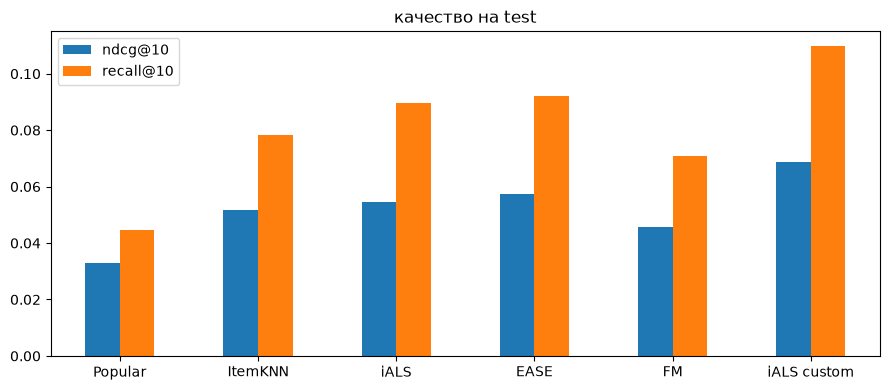

In [21]:
results[[f"ndcg@{K}", f"recall@{K}"]].plot.bar(figsize=(9, 4), rot=0, xlabel="", title="качество на test")
plt.tight_layout()
plt.show()

## 6. Выводы

- лучшая модель на test это iALS с кастомным таргетом: NDCG@10 = 0.0686, Recall@10 = 0.1097, дальше EASE (0.0575), iALS (0.0544), ItemKNN (0.0516), FM (0.0455) и популярность (0.0331), порядок такой же как на val
- из моделей которые учились только на кликах лучше всех EASE с $\lambda=500$
- у iALS лучше всего 32 фактора и $\alpha=10$, с 64 факторами уже хуже
- ItemKNN лучше работает без сжатия и с большим числом соседей, покрытие у него и у FM самое большое (0.24)
- FM хуже остальных персональных моделей, но лучше популярности, метаданные помогают: FM с признаками лучше чем FM только на id (0.0466 против 0.0381 NDCG@10 на val)
- кастомный таргет дает самый большой прирост: +26% NDCG@10 и +23% Recall@10 к базовому iALS на test при тех же гиперпараметрах, больше всего помогают показы без клика как слабый позитив и затухание по времени, а показы без клика как негатив хуже, чем если их совсем не учитывать
- популярность сильно хуже персональных моделей, хотя 10% видео собирают 63% кликов, покрытие у нее < 1%

ограничения:
- 1 сплит по времени и короткий test (6 дней)
- лог собран при работе рекомендательной системы Kuaishou, кликнуть можно только на показанное видео, модели которые учитывают показы частично выучивают политику этой системы, поэтому офлайн прирост может не перенестись в онлайн
- в ленте с 1 колонкой клик это просмотр > 7 сек, это слабый сигнал интереса
- новые юзеры исключены из оценки, холодный старт не проверяли
- сетки гиперпараметров небольшие, особенно у FM